# Ödev 29 - Capstone: GTSRB Trafik İşareti Sınıflandırma (CNN)

## Proje hakkında

**Problem:** Alman Trafik İşareti Tanıma veri setindeki (GTSRB) fotoğrafları 43 trafik işareti sınıfına ayıran bir CNN kurmak.

**Konu:** Görüntü verisi kontrolü (sınıf dağılımı, boyutlar, aynı işaretin ardışık kareleri), ROI kırpma, iz (track) bazında doğrulama ayrımı, Conv2D / MaxPooling2D, veri çoğaltma, EarlyStopping, resmi test seti ile değerlendirme ve Streamlit uygulaması.

**Metrik:** Resmi test setinde accuracy ve macro F1 (hedef %80).

**Veri:** Klasördeki `Train.csv` (39.209 satır), `Test.csv` (12.630 satır), `Meta.csv` ve `Train/`, `Test/` klasörleri (Kaggle GTSRB). Klasördeki 642 MB'lık arşiv bu ortama aktarılamadığı için aynı Kaggle dosyaları GitHub `Sainilapwar01/Traffic-Sign-Recognition` deposunun `dataset/` klasöründen alındı; dosya adları ve CSV'ler birebir aynı.

## Kütüphaneleri yüklüyor ve veriyi okuyoruz.

Kütüphaneleri yükleyip eğitim ve test listelerini okuyoruz.

In [1]:
import cv2 # fotoğraf okuma ve boyutlandırma
import pandas as pd # tablo işlemleri
import numpy as np # matematik paketi
import matplotlib.pyplot as plt # grafik çizimi
import seaborn as sns # sns havalı grafik oluşturma paketi

train=pd.read_csv('Train.csv') # eğitim listesi
test=pd.read_csv('Test.csv') # resmi test listesi
print(train.shape, test.shape) # boyutlar
print('Sınıf sayısı:', len(train.ClassId.unique())) # 43 sınıf
train.head() # ilk satırlar

(39209, 8) (12630, 8)
Sınıf sayısı: 43


,Width,Height,Roi.X1,Roi.Y1,Roi.X2,Roi.Y2,ClassId,Path
0,27,26,5,5,22,20,20,Train/20/00020_00000_00000.png
1,28,27,5,6,23,22,20,Train/20/00020_00000_00001.png
2,29,26,6,5,24,21,20,Train/20/00020_00000_00002.png
3,28,27,5,6,23,22,20,Train/20/00020_00000_00003.png
4,28,26,5,5,23,21,20,Train/20/00020_00000_00004.png


**Sonuç:** Eğitim listesinde 39.209, resmi test listesinde 12.630 fotoğraf var; 43 trafik işareti sınıfı bulunuyor. Klasördeki `Train.csv` ve `Test.csv` ile kullanılan dosyalar birebir aynı.

## Veri kontrolü

Eski çözüm `Train.csv`'nin ilk 1.000 satırını kullanıyordu. Bu satırların hangi sınıflardan geldiğine bakıyoruz.

In [2]:
print('İlk 1000 satırdaki sınıflar:', sorted(train.ClassId.head(1000).unique())) # eski çözümün verisi
print(train.ClassId.head(1000).value_counts()) # sınıf sayıları

İlk 1000 satırdaki sınıflar: [np.int64(0), np.int64(1), np.int64(20)]
ClassId
1     430
20    360
0     210
Name: count, dtype: int64


**Sonuç:** Eski çözümün kullandığı ilk 1.000 satırda 43 sınıfın sadece **3'ü** (0, 1 ve 20) var, çünkü `Train.csv` sınıflara göre sıralı. Model 43 çıkışlı kurulduğu halde sadece 3 sınıf görmüştü; %68'lik doğrulama sonucu bu yüzden anlamlı değildi. Bu çalışmada 39.209 fotoğrafın tamamı kullanılıyor.

Bütün eğitim verisinde sınıf dağılımına ve fotoğraf boyutlarına bakıyoruz.

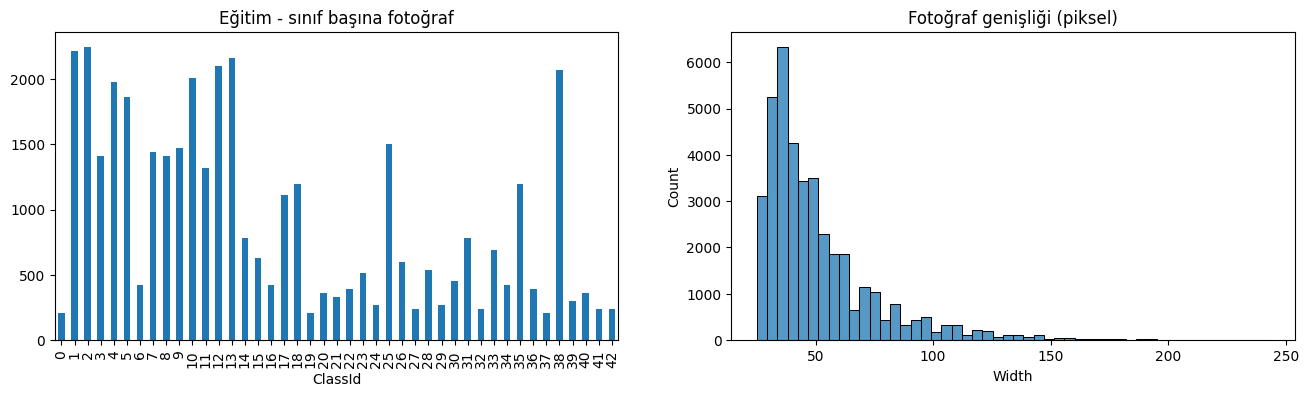

En az / en çok fotoğraflı sınıf: 210 / 2250
Genişlik aralığı: 25 - 243 | yükseklik: 25 - 225


In [3]:
fig,ax=plt.subplots(1,2,figsize=(16,4)) # iki grafik
train.ClassId.value_counts().sort_index().plot(kind='bar', ax=ax[0], title='Eğitim - sınıf başına fotoğraf') # dağılım
sns.histplot(train.Width, bins=50, ax=ax[1]) # genişlik
ax[1].set_title('Fotoğraf genişliği (piksel)') # başlık
plt.show() # göster
print('En az / en çok fotoğraflı sınıf:', train.ClassId.value_counts().min(), '/', train.ClassId.value_counts().max()) # dengesizlik
print('Genişlik aralığı:', train.Width.min(), '-', train.Width.max(), '| yükseklik:', train.Height.min(), '-', train.Height.max()) # boyutlar

**Sonuç:** Sınıflar dengesiz: en az fotoğraflı sınıfta 210, en çok olanda 2.250 fotoğraf var (hız sınırları çok, bazı uyarı işaretleri az). Fotoğraf boyutları 25 ile 243 piksel arasında değişiyor; hepsi aynı boyuta getirilmeli.

Dosya adları `sınıf_iz_kare` biçiminde: aynı fiziksel işaretin araçtan çekilmiş 30 ardışık karesi aynı izi (track) paylaşıyor. Bunu kontrol ediyoruz.

İz sayısı: 1307 | iz başına kare: 29 - 30


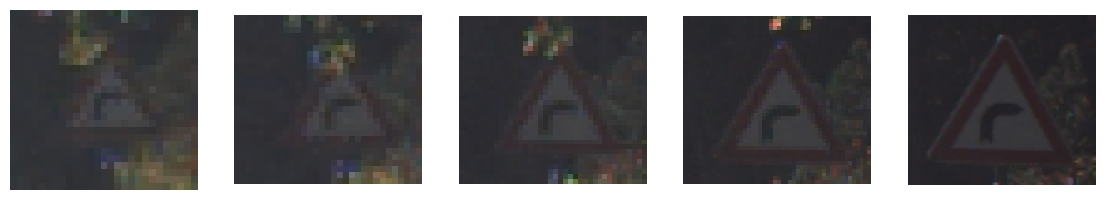

In [4]:
train['iz']=train.Path.str.split('/').str[-1].str[:11] # ör. 00020_00000 = sınıf 20, iz 0
iz=train.groupby('iz').Path.count() # iz başına kare
print('İz sayısı:', len(iz), '| iz başına kare:', iz.min(), '-', iz.max()) # bilgi
plt.figure(figsize=(14,2.5)) # grafik
for i, p in enumerate(train[train.iz=='00020_00000'].Path.iloc[::6]): # aynı izin 5 karesi
    plt.subplot(1,5,i+1) # alt grafik
    plt.imshow(cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)) # RGB
    plt.axis('off') # eksenleri gizle
plt.show() # göster

**Sonuç:** Eğitim verisi 1.307 izden oluşuyor ve her izde aynı işaretin 29-30 ardışık karesi var; örnekteki kareler neredeyse aynı fotoğraf. Rastgele bölmede bu kareler hem eğitime hem doğrulamaya düşer ve doğrulama sonucu şişer.

Fotoğraflarda işaretin yerini gösteren ROI (Roi.X1...Roi.Y2) bilgisi var. Fotoğrafları bu alana göre kırpıp 32x32 boyutuna getiriyor ve 255'e bölüyoruz.

In [5]:
S=32 # fotoğraf boyutu
def oku(tablo): # fotoğrafları diziye çevir
    x=[] # fotoğraflar
    for p, x1, y1, x2, y2 in zip(tablo.Path, tablo['Roi.X1'], tablo['Roi.Y1'], tablo['Roi.X2'], tablo['Roi.Y2']): # her fotoğraf
        resim=cv2.cvtColor(cv2.imread(p), cv2.COLOR_BGR2RGB)[y1:y2+1, x1:x2+1] # oku ve işarete göre kırp
        x.append(cv2.resize(resim, (S,S))/255.0) # boyutlandır ve normalize et
    return np.array(x, dtype='float32') # dizi

x_hepsi=oku(train) # bütün eğitim fotoğrafları
x_test=oku(test) # resmi test fotoğrafları
y_hepsi=train.ClassId.values # eğitim etiketleri
y_test=test.ClassId.values # test etiketleri
print(x_hepsi.shape, x_test.shape) # boyutlar

(39209, 32, 32, 3) (12630, 32, 32, 3)


**Sonuç:** Fotoğraflar ROI bilgisine göre kırpılıp 32x32x3 boyutunda diziye çevrildi: 39.209 eğitim ve 12.630 resmi test fotoğrafı.

## Veriyi bölüyoruz

Eski çözüm `validation_split` ile rastgele bölme yapıyordu; aynı işaretin neredeyse aynı kareleri hem eğitimde hem doğrulamada olduğu için doğrulama sonucu olduğundan iyi görünür. Burada doğrulama için **izlerin %10'unu** bütün kareleriyle ayırıyoruz. Asıl test olarak GTSRB'nin ayrı çekilmiş resmi test setini kullanıyoruz.

In [6]:
from sklearn.model_selection import train_test_split # veriyi bölme
izler=train[['iz','ClassId']][train[['iz','ClassId']].duplicated()==False] # her iz bir kez
iz_egitim, iz_dogrulama = train_test_split(izler.iz, test_size=0.1, random_state=42, stratify=izler.ClassId) # iz bazında bölme
egitim_mi=train.iz.isin(iz_egitim).values # eğitimdeki satırlar
x_train, y_train = x_hepsi[egitim_mi], y_hepsi[egitim_mi] # eğitim
x_val, y_val = x_hepsi[egitim_mi==False], y_hepsi[egitim_mi==False] # doğrulama
print(len(x_train), len(x_val), len(x_test)) # boyutlar
print('Ortak iz:', len(set(iz_egitim) & set(iz_dogrulama))) # sızıntı kontrolü

35280 3929 12630
Ortak iz: 0


**Sonuç:** İzlerin %10'u doğrulamaya ayrıldı: 35.280 eğitim, 3.929 doğrulama fotoğrafı; ortak iz yok. Resmi test seti (12.630) eğitimde hiç kullanılmıyor.

## CNN modeli

Küçük döndürme, kaydırma ve yakınlaştırma ile çoğaltma yapan (çevirme yok, çünkü sağa ve sola dönüş işaretleri birbirine dönüşür) ve 4 evrişim katmanı olan bir CNN kuruyoruz.

Epoch 1/30


552/552 - 41s - 75ms/step - accuracy: 0.5166 - loss: 1.6639 - val_accuracy: 0.8636 - val_loss: 0.4354


Epoch 2/30


552/552 - 39s - 71ms/step - accuracy: 0.9029 - loss: 0.3240 - val_accuracy: 0.9717 - val_loss: 0.1226


Epoch 3/30


552/552 - 39s - 71ms/step - accuracy: 0.9558 - loss: 0.1513 - val_accuracy: 0.9794 - val_loss: 0.1032


... (7 outputs left out)

552/552 - 41s - 75ms/step - accuracy: 0.9842 - loss: 0.0526 - val_accuracy: 0.9799 - val_loss: 0.0996


Epoch 8/30


552/552 - 41s - 74ms/step - accuracy: 0.9860 - loss: 0.0458 - val_accuracy: 0.9807 - val_loss: 0.0988


Eğitilen epoch: 8


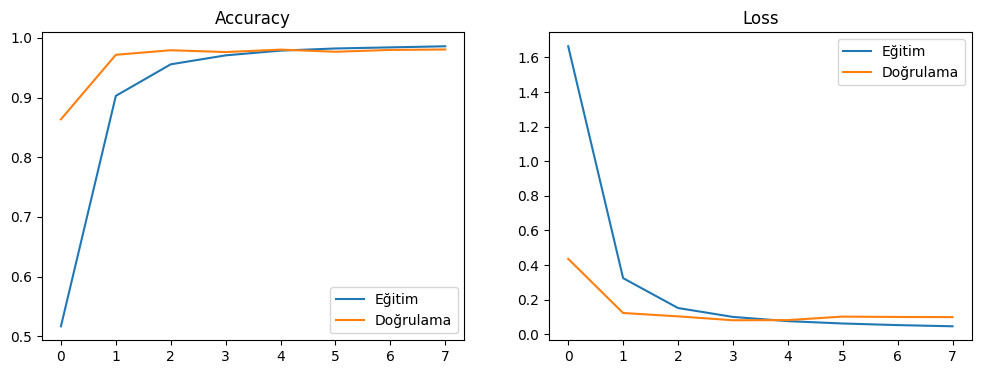

In [7]:
from tensorflow.keras.models import Sequential # sıralı model
from tensorflow.keras.layers import Conv2D, Dense, Flatten, Input, MaxPooling2D # derslerdeki katmanlar
from tensorflow.keras.layers import RandomRotation, RandomTranslation, RandomZoom # veri çoğaltma (sadece eğitimde)
from tensorflow.keras.callbacks import EarlyStopping # erken durdurma
import tensorflow as tf # tensorflow
tf.keras.utils.set_random_seed(42) # tekrarlanabilir sonuç
tf.config.experimental.enable_op_determinism() # her çalıştırmada aynı sonuç
cnn=Sequential() # boş model
cnn.add(Input(shape=(S,S,3))) # giriş
cnn.add(RandomRotation(0.04)) # en fazla yaklaşık 15 derece döndürme
cnn.add(RandomTranslation(0.1, 0.1)) # %10 kaydırma
cnn.add(RandomZoom(0.1)) # %10 yakınlaştırma
cnn.add(Conv2D(32, kernel_size=(3,3), activation='relu', padding='same')) # 1. evrişim
cnn.add(Conv2D(32, kernel_size=(3,3), activation='relu', padding='same')) # 2. evrişim
cnn.add(MaxPooling2D(pool_size=(2,2))) # 32 -> 16
cnn.add(Conv2D(64, kernel_size=(3,3), activation='relu', padding='same')) # 3. evrişim
cnn.add(Conv2D(64, kernel_size=(3,3), activation='relu', padding='same')) # 4. evrişim
cnn.add(MaxPooling2D(pool_size=(2,2))) # 16 -> 8
cnn.add(Flatten()) # satıra aç
cnn.add(Dense(128, activation='relu')) # gizli katman
cnn.add(Dense(43, activation='softmax')) # çıkış: 43 sınıf
cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy']) # derle
erken=EarlyStopping(monitor='val_loss', patience=4, restore_best_weights=True) # erken durdurma
history=cnn.fit(x_train, y_train, validation_data=(x_val, y_val), epochs=30, batch_size=64, callbacks=[erken], verbose=2) # eğit, her epoch ekrana yazılır
print('Eğitilen epoch:', len(history.history['loss'])) # kaç epoch
fig=plt.figure(figsize=(12,4)) # grafik
ax=fig.add_subplot(1,2,1) # 1. grafik
ax.plot(history.history['accuracy'], label='Eğitim') # eğitim doğruluğu
ax.plot(history.history['val_accuracy'], label='Doğrulama') # doğrulama doğruluğu
ax.set_title('Accuracy') # başlık
ax.legend() # açıklama
ax=fig.add_subplot(1,2,2) # 2. grafik
ax.plot(history.history['loss'], label='Eğitim') # eğitim kaybı
ax.plot(history.history['val_loss'], label='Doğrulama') # doğrulama kaybı
ax.set_title('Loss') # başlık
ax.legend() # açıklama
plt.show() # göster

**Sonuç:** Her epoch artık ekranda görünüyor. Doğrulama doğruluğu ilk epoch'ta %86,4, ikinci epoch'ta %97,2 oldu. Doğrulama kaybı en düşük değerine (0,081) 4. epoch'ta indi; sonraki 4 epoch'ta iyileşmediği için EarlyStopping eğitimi 8. epoch'ta durdurup 4. epoch'un ağırlıklarına döndü. Eğitim doğruluğu %98,6'ya çıkarken doğrulama %97,6-98,1 arasında kaldı.

Resmi test setinde sonuçları ve en çok karıştırılan sınıfları çıkarıyoruz.

In [8]:
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix # başarı ölçüleri
isimler=['Hız sınırı 20','Hız sınırı 30','Hız sınırı 50','Hız sınırı 60','Hız sınırı 70','Hız sınırı 80','Hız sınırı 80 sonu','Hız sınırı 100','Hız sınırı 120','Sollama yasak', # 0-9
         'Kamyonlar için sollama yasak','Kavşakta geçiş hakkı','Ana yol','Yol ver','Dur','Taşıt giremez','Kamyon giremez','Girişi olmayan yol','Dikkat','Sola tehlikeli viraj', # 10-19
         'Sağa tehlikeli viraj','Çift viraj','Engebeli yol','Kaygan yol','Sağdan daralan yol','Yol çalışması','Trafik ışığı','Yaya geçidi','Okul geçidi','Bisiklet geçidi', # 20-29
         'Buzlanma','Vahşi hayvan','Tüm yasakların sonu','Sağa dönünüz','Sola dönünüz','İleri gidiniz','İleri veya sağa','İleri veya sola','Sağdan gidiniz','Soldan gidiniz', # 30-39
         'Döner kavşak','Sollama yasağı sonu','Kamyon sollama yasağı sonu'] # 40-42
sonuc=pd.DataFrame(columns=['Accuracy','F1 (macro)']) # tablo
for isim, xx, yy in [('Eğitim',x_train,y_train), ('Doğrulama (iz bazında)',x_val,y_val), ('Resmi test',x_test,y_test)]: # üç küme
    t=cnn.predict(xx, verbose=0).argmax(axis=1) # tahmin
    sonuc.loc[isim]=[accuracy_score(yy,t), f1_score(yy,t,average='macro')] # sonuçlar
tahmin=cnn.predict(x_test, verbose=0).argmax(axis=1) # test tahmini
cm=confusion_matrix(y_test, tahmin) # karışıklık matrisi
np.fill_diagonal(cm, 0) # doğruları sıfırla, sadece hatalar kalsın
hata=pd.DataFrame([(isimler[i], isimler[j], cm[i,j]) for i in range(43) for j in range(43) if cm[i,j]>0], columns=['Gerçek','Tahmin','Adet']).sort_values('Adet', ascending=False) # hata çiftleri
print(hata.head(8).to_string(index=False)) # en sık 8 hata
sinif_dogru=pd.Series([accuracy_score(y_test[y_test==k], tahmin[y_test==k]) for k in range(43)], index=isimler).sort_values() # sınıf başına doğruluk
print(sinif_dogru.head(5).round(3)) # en zor 5 sınıf
sonuc.astype(float).round(3) # tablo

              Gerçek               Tahmin  Adet
            Buzlanma Kavşakta geçiş hakkı    27
         Yaya geçidi         Trafik ışığı    27
Sola tehlikeli viraj           Kaygan yol    27
       Hız sınırı 60        Hız sınırı 80    26
  Girişi olmayan yol      İleri veya sola    21
        Trafik ışığı               Dikkat    20
            Buzlanma      Bisiklet geçidi    19
          Çift viraj               Dikkat    17
Yaya geçidi             0.467
Buzlanma                0.480
Sola tehlikeli viraj    0.500
Çift viraj              0.667
Sollama yasağı sonu     0.767
dtype: float64


,Accuracy,F1 (macro)
Eğitim,0.995,0.995
Doğrulama (iz bazında),0.976,0.977
Resmi test,0.960,0.923


**Sonuç:** Model resmi test setinde **yaklaşık %96,0 accuracy** ve 0,923 macro F1 verdi (eğitim %99,5, iz bazında doğrulama %97,6). En sık hatalar birbirine benzeyen işaretler arasında: 'Buzlanma' ile 'Kavşakta geçiş hakkı', 'Yaya geçidi' ile 'Trafik ışığı', 'Sola tehlikeli viraj' ile 'Kaygan yol' (aynı kırmızı üçgen çerçeve, içindeki sembol farklı) ve '60' ile '80' hız sınırı (26 hata). En zor sınıflar 'Yaya geçidi' (%46,7), 'Buzlanma' (%48,0) ve 'Sola tehlikeli viraj' (%50,0); bunlar eğitimde az fotoğrafı olan sınıflar. Macro F1'in accuracy'den düşük olması da bu az örnekli sınıflardaki hatalardan kaynaklanıyor.

Yanlış tahmin edilen test fotoğraflarına bakıyoruz.

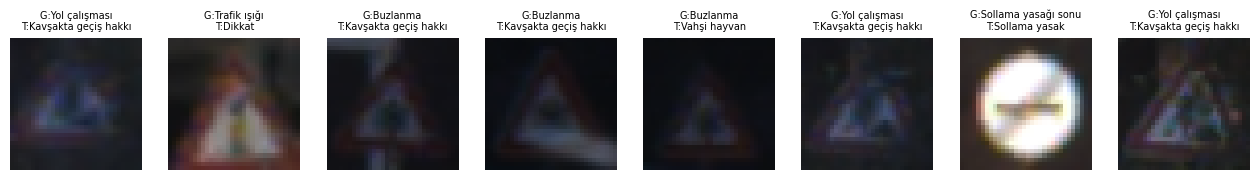

In [9]:
yanlis=np.where(tahmin!=y_test)[0][:8] # ilk 8 hata
plt.figure(figsize=(16,3)) # grafik boyutu
for i, j in enumerate(yanlis): # her hata
    plt.subplot(1,8,i+1) # alt grafik
    plt.imshow(x_test[j]) # fotoğraf
    plt.title('G:'+isimler[y_test[j]]+'\nT:'+isimler[tahmin[j]], fontsize=7) # gerçek ve tahmin
    plt.axis('off') # eksenleri gizle
plt.show() # göster

**Sonuç:** Hatalı tahminlerin çoğu karanlık veya bulanık çekilmiş üçgen uyarı işaretleri; 32x32'ye küçültülünce üçgenin içindeki sembol seçilemiyor ve model bunları sık sık 'Kavşakta geçiş hakkı' olarak tahmin ediyor. Parlak ışık altında çekilen 'Sollama yasağı sonu' işareti de üstündeki çizgi görünmediği için 'Sollama yasak' sanılmış.

Modeli kaydediyoruz.

In [10]:
cnn.save('gtsrb_cnn_rwz.keras') # model
print('Kaydedildi: gtsrb_cnn_rwz.keras') # bilgi

Kaydedildi: gtsrb_cnn_rwz.keras


## Sonuçların Değerlendirilmesi

| Küme | Accuracy | F1 (macro) |
|---|---|---|
| Eğitim | yaklaşık 0,995 | yaklaşık 0,995 |
| Doğrulama (iz bazında) | yaklaşık 0,976 | yaklaşık 0,977 |
| Resmi test | yaklaşık 0,960 | yaklaşık 0,923 |

**Hedef (%80) aşıldı:** CNN, GTSRB'nin resmi test setinde yaklaşık %96,0 doğruluk verdi. Eğitim 8 epoch sürdü, en iyi ağırlıklar 4. epoch'tan alındı.

- **Veri seçimi hatası:** Eski çözüm `Train.csv`'nin ilk 1.000 satırını aldığı için 43 sınıftan sadece 3'ünü görüyordu.
- **Sızıntı:** Eski çözümde aynı işaretin ardışık kareleri rastgele bölmeyle hem eğitime hem doğrulamaya düşüyordu. Burada doğrulama iz bazında ayrıldı ve son değerlendirme resmi test setiyle yapıldı.
- Fotoğraflar ROI'ye göre kırpıldı. Veri çoğaltmada yatay çevirme kullanılmadı, çünkü sağa ve sola yön işaretleri birbirine dönüşür.
- **Zayıf yön:** Az fotoğraflı üçgen uyarı işaretleri (Yaya geçidi, Buzlanma, Sola tehlikeli viraj) karanlık ve bulanık fotoğraflarda karıştırılıyor.
- Eğitimde `tf.keras.utils.set_random_seed(42)` ve `enable_op_determinism()` kullanıldı. Farklı bilgisayar, TensorFlow sürümü veya GPU'da sonuçlar küçük farklarla değişebilir; bu yüzden değerler yaklaşık verildi.

**Kaydedilen dosyalar:** `gtsrb_cnn_rwz.keras`, `app_rwz.py`